# Visualisasi Sebaran Resistivitas

# 1. Import Library dan Package

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import pygmt
INPUT_DIR = r"C:\KULIAH\KULTER 2\MT\trial_datashifa\edis\AMT\03. EXTRACT DEPTH"
OUTPUT_GMT = r"C:\KULIAH\KULTER 2\MT\trial_datashifa\edis\AMT\04. PLOT HORIZONTAL\GMT_CALCULATE 1D HORIZONTAL.csv"
csv_files = glob.glob(os.path.join(INPUT_DIR, "*_EXTRACT with TOLERANCE DEPTH*.csv"))
df_master = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)
os.makedirs(os.path.dirname(OUTPUT_GMT), exist_ok=True)
df_master.to_csv(OUTPUT_GMT, index=False)
print(f"File siap untuk PyGMT: {OUTPUT_GMT}")

File siap untuk PyGMT: C:\KULIAH\KULTER 2\MT\trial_datashifa\edis\AMT\04. PLOT HORIZONTAL\GMT_CALCULATE 1D HORIZONTAL.csv


In [2]:
import sys
print(sys.executable)

C:\Users\axioo\anaconda3\envs\mtpy\python.exe


# 2. Pemrosesan Data dan Plotting Peta PyGMT


[SUKSES] Peta disimpan di: GMT_PSEUDOSECTION HORIZONTAL MAP.png


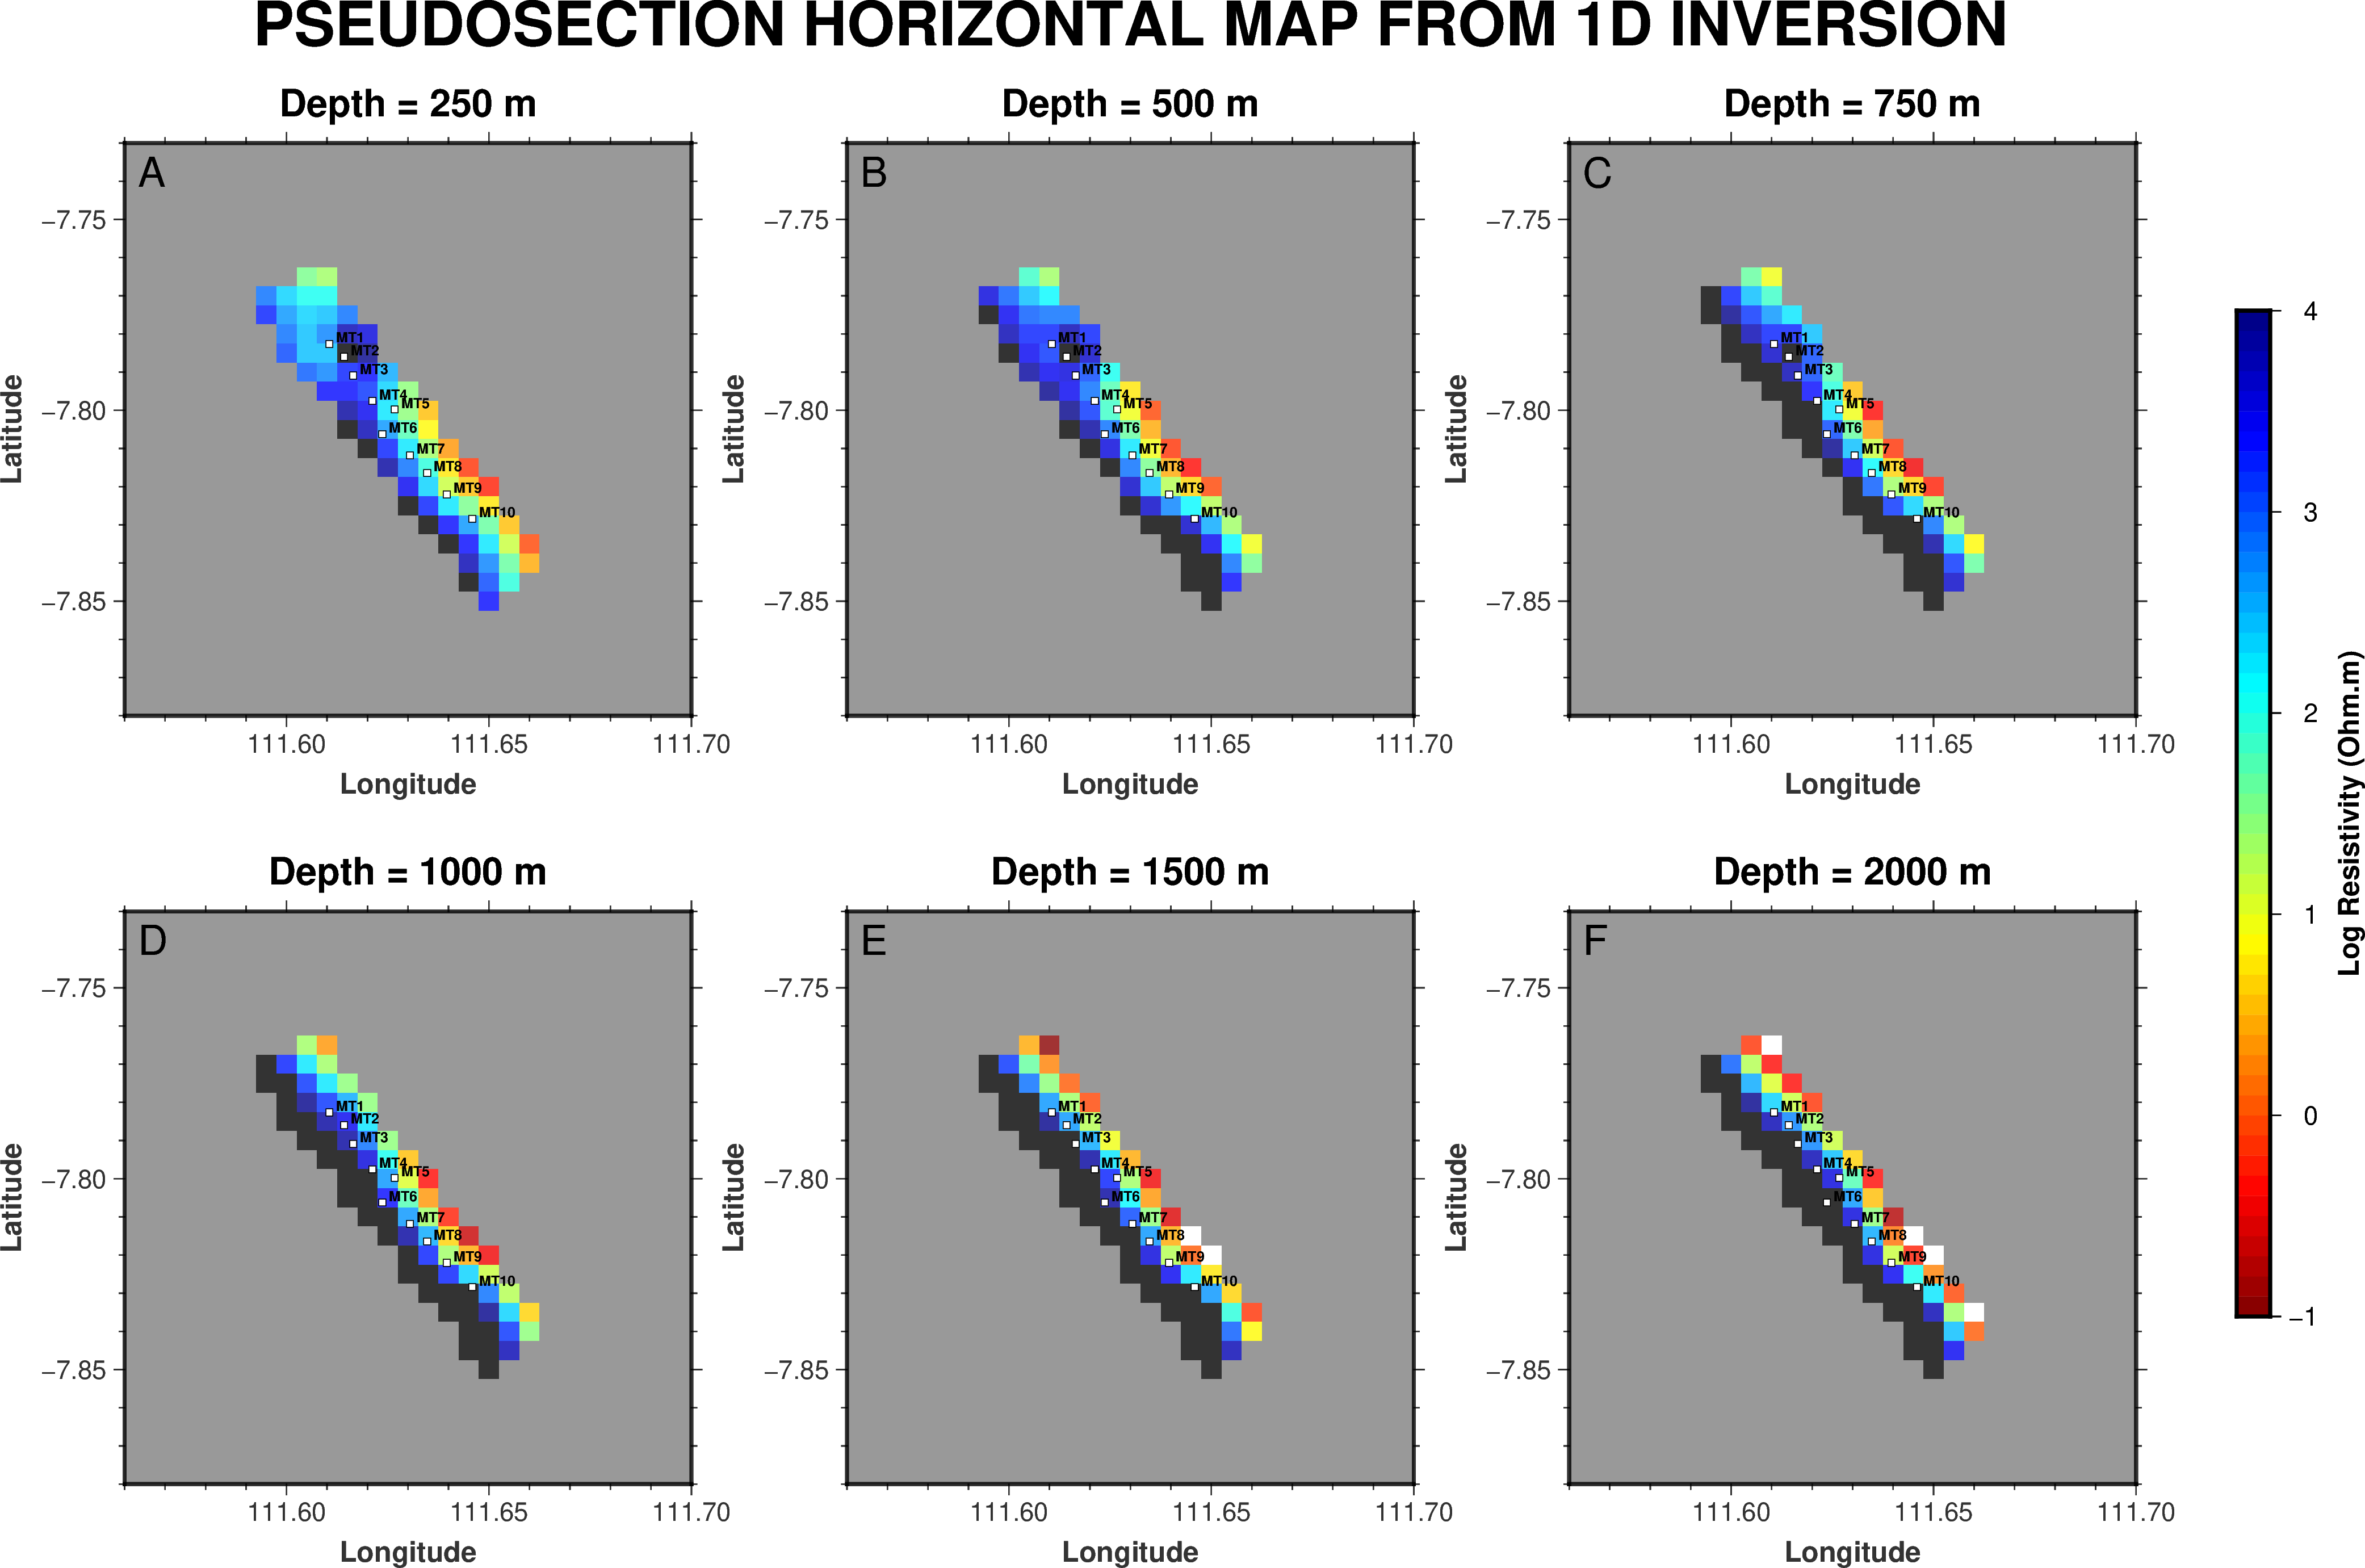

In [3]:
FILE_INPUT = r"C:\KULIAH\KULTER 2\MT\trial_datashifa\edis\AMT\04. PLOT HORIZONTAL\GMT_CALCULATE 1D HORIZONTAL.csv"
OUTPUT_DIR = r"C:\KULIAH\KULTER 2\MT\trial_datashifa\edis\AMT\04. PLOT HORIZONTAL"
NAMA_FILE_OUTPUT = "GMT_PSEUDOSECTION HORIZONTAL MAP.png"
DEPTHS_TO_PLOT = [250, 500, 750, 1000, 1500, 2000]
df = pd.read_csv(FILE_INPUT)
margin = 0.05
res_grid = 0.01
REGION = [
    np.floor((df['Longitude'].min() - margin) / res_grid) * res_grid,
    np.ceil((df['Longitude'].max() + margin) / res_grid) * res_grid,
    np.floor((df['Latitude'].min() - margin) / res_grid) * res_grid,
    np.ceil((df['Latitude'].max() + margin) / res_grid) * res_grid
]
os.chdir(OUTPUT_DIR)
fig = pygmt.Figure()
pygmt.config(
    MAP_HEADING_OFFSET="0.5c",
    MAP_TITLE_OFFSET="0.4c",
    FONT_HEADING="26p,Helvetica-Bold,black",
    FONT_TITLE="16p,Helvetica-Bold,black",
    FONT_LABEL="12p,Helvetica-Bold,black",
    MAP_LABEL_OFFSET="0.3c"
)
pygmt.makecpt(cmap="jet", series="-1/4/0.1", reverse=True, output="GMT_RESISTIVITY.cpt")
with fig.subplot(nrows=2, ncols=3, figsize=("30c", "20c"), margins=["0.5c", "0.8c"], title="PSEUDOSECTION HORIZONTAL MAP FROM 1D INVERSION", frame=["WSne", "xaf+lLongitude", "yaf+lLatitude"], autolabel="A+jTL+o0.2c/0.2c"):
    for i, depth in enumerate(DEPTHS_TO_PLOT):
        with fig.set_panel(panel=i):
            subset_df = df[np.isclose(df['Depth'], depth, atol=2.0)]
            if len(subset_df) > 2:
                block = pygmt.blockmedian(data=subset_df[["Longitude", "Latitude", "Log Resistivity"]], region=REGION, spacing="0.005")
                grid = pygmt.surface(data=block, region=REGION, spacing="0.005")
                # --- FIX: batasi grid hanya di sekitar garis lintasan stasiun ---
                # Pakai PCA dari koordinat SEMUA stasiun unik (tidak bergantung urutan baris di df,
                # yang bisa keliru kalau df hasil concat file per-stasiun dengan urutan alfabetis)
                station_coords = df[['Station', 'Longitude', 'Latitude']].drop_duplicates(subset='Station')
                pts = station_coords[['Longitude', 'Latitude']].to_numpy()
                centroid = pts.mean(axis=0)
                _, _, vh = np.linalg.svd(pts - centroid)
                direction = vh[0]  # arah vektor utama garis lintasan
                perp_dir = np.array([-direction[1], direction[0]])  # arah tegak lurus garis
                proj_stations = (pts - centroid) @ direction
                t_min, t_max = proj_stations.min(), proj_stations.max()

                gx, gy = grid.x.values, grid.y.values  # ganti ke grid.lon/grid.lat kalau nama koordinatnya beda
                lon2d, lat2d = np.meshgrid(gx, gy)
                grid_pts = np.column_stack([lon2d.ravel(), lat2d.ravel()]) - centroid
                proj_grid = (grid_pts @ direction).reshape(lon2d.shape)
                perp_grid = np.abs(grid_pts @ perp_dir).reshape(lon2d.shape)

                BUFFER_PERP_DEG = 0.01    # jarak tegak lurus dari garis yang masih ditampilkan (~1 km, sesuaikan)
                BUFFER_ALONG_DEG = 0.02   # margin ekstra di ujung-ujung garis, dalam derajat (~2 km, sesuaikan)
                mask = (perp_grid <= BUFFER_PERP_DEG) & (proj_grid >= t_min - BUFFER_ALONG_DEG) & (proj_grid <= t_max + BUFFER_ALONG_DEG)
                grid = grid.where(mask)
                fig.grdimage(grid=grid, cmap="GMT_RESISTIVITY.cpt", transparency=20)
            fig.coast(shorelines="0.5p,black", region=REGION, resolution='i')
            fig.basemap(region=REGION, frame=[f"+tDepth = {int(depth)} m"])
            if not subset_df.empty:
                fig.plot(x=subset_df['Longitude'], y=subset_df['Latitude'], style="s0.15c", fill="white", pen="black")
                fig.text(x=subset_df['Longitude'], y=subset_df['Latitude'], text=subset_df['Station'], font="6p,Helvetica-Bold,black", offset="0.1c/0.1c", justify="ML")
fig.colorbar(cmap="GMT_RESISTIVITY.cpt", position="JMR+o1.5c/0c+w15c/0.5c", frame=["a1", "x+lLog Resistivity (Ohm.m)"])
fig.savefig(NAMA_FILE_OUTPUT, crop="+m0.5c")
print(f"\n[SUKSES] Peta disimpan di: {NAMA_FILE_OUTPUT}")
fig.show()

In [5]:
print("Total baris:", len(df))
print("Baris dengan Lon/Lat valid:", df[['Longitude','Latitude']].notna().all(axis=1).sum())
print("Jumlah Station unik:", df['Station'].nunique())
print(df['Station'].unique())

# cek apakah ADA baris yang valid sama sekali
print(df[df['Longitude'].notna()].head())

Total baris: 138
Baris dengan Lon/Lat valid: 0
Jumlah Station unik: 10
<StringArray>
['MT10', 'MT1', 'MT2', 'MT3', 'MT4', 'MT5', 'MT6', 'MT7', 'MT8', 'MT9']
Length: 10, dtype: str
Empty DataFrame
Columns: [Station, Depth, Resistivity Mean, Log Resistivity, Latitude, Longitude, Elevation]
Index: []


In [17]:
print(df.columns.tolist())
print(df.head())

['Station,Depth,Resistivity Mean,Log Resistivity,Latitude,Longitude,Elevation']
  Station,Depth,Resistivity Mean,Log Resistivity,Latitude,Longitude,Elevation
0  MT6,250.0,1708.888,3.233,-7.80625,111.623667,7...                         
1  MT6,500.0,2498.689,3.398,-7.80625,111.623667,7...                         
2  MT6,750.0,4428.076,3.646,-7.80625,111.623667,7...                         
3  MT6,1000.0,8638.376,3.936,-7.80625,111.623667,...                         
4  MT6,1250.0,21423.475,4.331,-7.80625,111.623667...                         


In [18]:
print(df.dtypes)
print(df['Longitude'].unique()[:10])

Station,Depth,Resistivity Mean,Log Resistivity,Latitude,Longitude,Elevation    str
dtype: object


KeyError: 'Longitude'

In [12]:
with open(FILE_INPUT, encoding='utf-8', errors='ignore') as f:
    for i, line in enumerate(f):
        print(line)
        if i > 3: break

Station;Depth;Resistivity Mean;Log Resistivity;Latitude;Longitude;Elevation

MT6;250.0;1.708.888;3.233;-780.625;111.623.667;749.171

MT6;500.0;2.498.689;3.398;-780.625;111.623.667;749.171

MT6;750.0;4.428.076;3.646;-780.625;111.623.667;749.171

MT6;1000.0;8.638.376;3.936;-780.625;111.623.667;749.171



In [14]:
with open(r"C:\KULIAH\KULTER 2\MT\trial-2\edis\AMT\03. EXTRACT DEPTH\MT6_EXTRACT with TOLERANCE DEPTH.csv", encoding='utf-8') as f:
    for i, line in enumerate(f):
        print(line)
        if i > 3: break

Station;Depth;Resistivity Mean;Log Resistivity;Latitude;Longitude;Elevation

MT6;250.0;1.708.888;3.233;-780.625;111.623.667;749.171

MT6;500.0;2.498.689;3.398;-780.625;111.623.667;749.171

MT6;750.0;4.428.076;3.646;-780.625;111.623.667;749.171

MT6;1000.0;8.638.376;3.936;-780.625;111.623.667;749.171

